Imports

In [367]:
from ydata_profiling import ProfileReport
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Importing data and making data profile

In [368]:
DATA_DIR = Path("..") / "data"
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")

In [369]:
REPORTS_DIR = Path("..") / "reports"
report_path_f = REPORTS_DIR / "freight_profile.html"
report_path_w = REPORTS_DIR / "weather_profile.html"
if not report_path_f.exists():
    profile_freight = ProfileReport(df_freight, title="Rhine Freight - Data Profile", explorative=True)
    profile_freight.to_file(report_path_f)
    profile_weather = ProfileReport(df_weather, title="Weather Data Basel - Data Profile", explorative=True)
    profile_weather.to_file(report_path_w)

exploring

In [370]:
df_freight.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar'],
      dtype='object')

# Missing values

In [371]:
df_freight.shape


(1713, 8)

In [372]:
df_freight.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1713 entries, 0 to 1712
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          1469 non-null   object 
 1   Freight       1454 non-null   float64
 2   Mogas_Flat    1469 non-null   float64
 3   Brent_flat    1469 non-null   float64
 4   Diesel_Flat   1469 non-null   float64
 5   Heating_Flat  1469 non-null   float64
 6   Kaub_level    1456 non-null   float64
 7   freight_ar    723 non-null    float64
dtypes: float64(7), object(1)
memory usage: 107.2+ KB


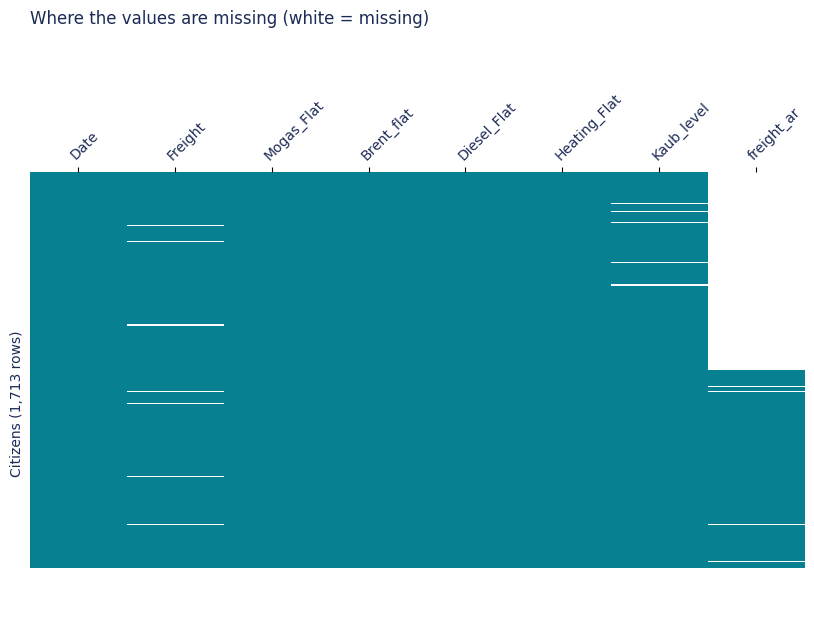

In [373]:
from matplotlib.colors import ListedColormap

NAVY, TEAL = "#1c2a56", "#078091"
FILL = TEAL                    # colour of the cells that have a value
TEXT = NAVY


SORT_ROWS = False              # True: group citizens with the same gaps together (blocks are easier to see)
present = df_freight.notna()
if SORT_ROWS:
    present = present.sort_values(list(present.columns), ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(present.values, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["white", FILL]), vmin=0, vmax=1)   # True = coloured, NaN = white

ax.set_xticks(range(present.shape[1]))
ax.xaxis.tick_top()
ax.set_xticklabels(present.columns, rotation=45, ha="left", rotation_mode="anchor", color=TEXT)
ax.set_ylabel(f"Citizens ({len(df_freight):,} rows)", color=TEXT)
ax.set_yticks([])
ax.set_title("Where the values are missing (white = missing)", loc="left", color=TEXT, pad=48)
for s in ax.spines.values():
    s.set_visible(False)

plt.show()

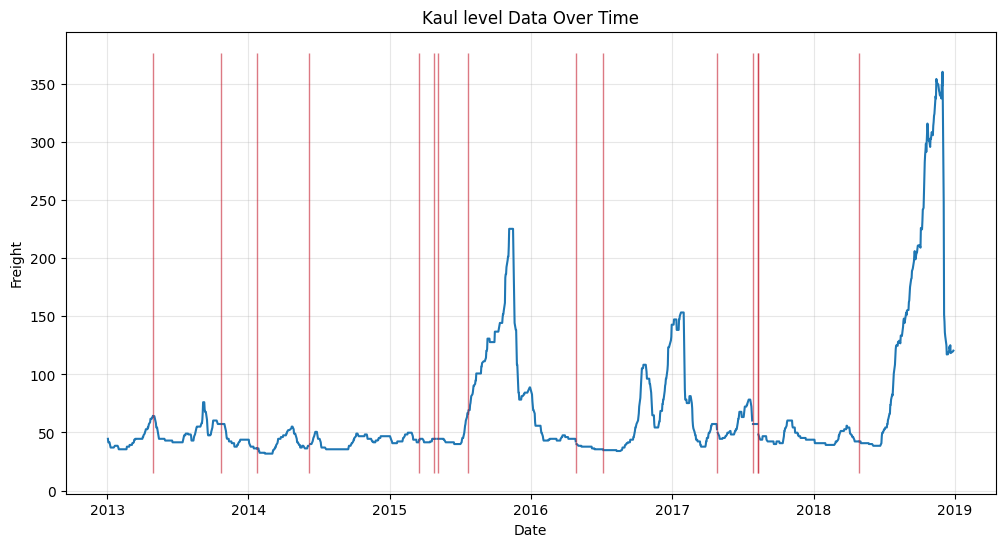

81     2013-04-30
198    2013-10-23
257    2014-01-23
347    2014-06-06
538    2015-03-17
          ...    
1708          NaT
1709          NaT
1710          NaT
1711          NaT
1712          NaT
Name: Date, Length: 259, dtype: datetime64[ns]


In [374]:
#looking at the gaps

df_freight["Date"] = pd.to_datetime(df_freight["Date"], format="%d/%m/%Y")
df_freight = df_freight.sort_values("Date")

missing_dates = df_freight.loc[df_freight["Freight"].isna(), "Date"]


fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_freight["Date"], df_freight['Freight'])
ax.set_title("Kaul level Data Over Time")
ax.vlines(missing_dates, *ax.get_ylim(), color="#c52030", alpha=0.6, lw=1,
          label=f"Missing ({len(missing_dates)} days)")
ax.set_xlabel("Date")
ax.set_ylabel("Freight")
ax.grid(True, alpha=0.3)
plt.show()
plt.close(fig)

print(missing_dates)

In [375]:
df_freight[df_freight['Date'].isin(missing_dates)]

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar
81,2013-04-30,NaN,559.305727,232.848837,525.593020,506.796741,334.0,NaN
198,2013-10-23,NaN,500.419638,235.078534,503.151672,491.096794,248.0,NaN
257,2014-01-23,NaN,499.689519,242.217171,508.038980,497.655332,215.0,NaN
347,2014-06-06,NaN,534.086080,239.305087,487.983963,477.286473,170.0,NaN
538,2015-03-17,NaN,502.542519,145.698166,471.538460,440.747821,206.0,NaN
...,...,...,...,...,...,...,...,...
1708,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1709,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1710,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1711,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN


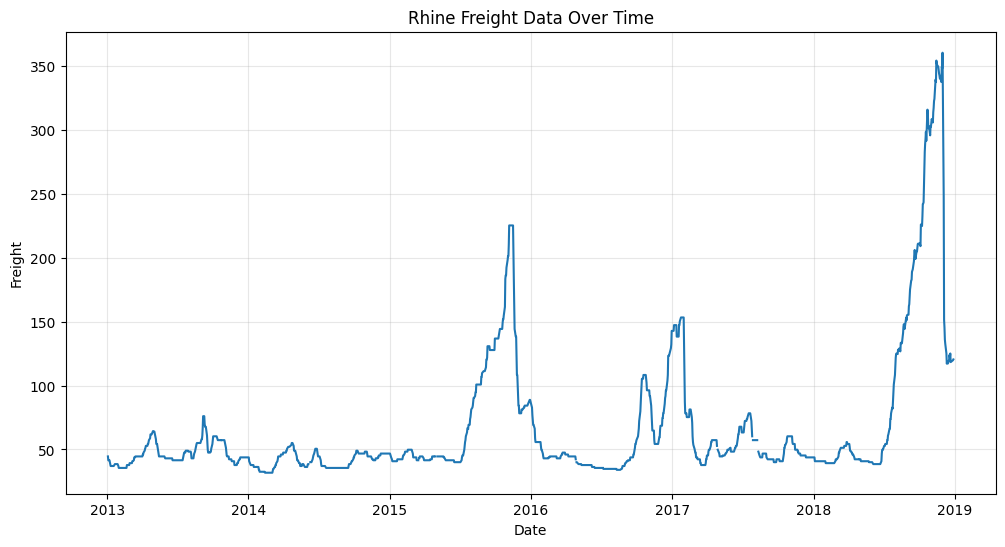

In [376]:
df_freight["Date"] = pd.to_datetime(df_freight["Date"], format="%d/%m/%Y")
df_freight = df_freight.sort_values("Date")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df_freight["Date"], df_freight['Freight'])
ax.set_title("Rhine Freight Data Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Freight")
ax.grid(True, alpha=0.3)
plt.show()
plt.close(fig)

- no paired missing values
- unprobable that missings = 0 as seen in the figure
- Missings in the freight_ar before 2016, can be due to new implementation of the tariff at the ar region

Missing values in the target variables (Freight and freight_ar) mean that that training rows are not useful - delete them
Kaub_level missing values can maybe be estimated by surrounding values

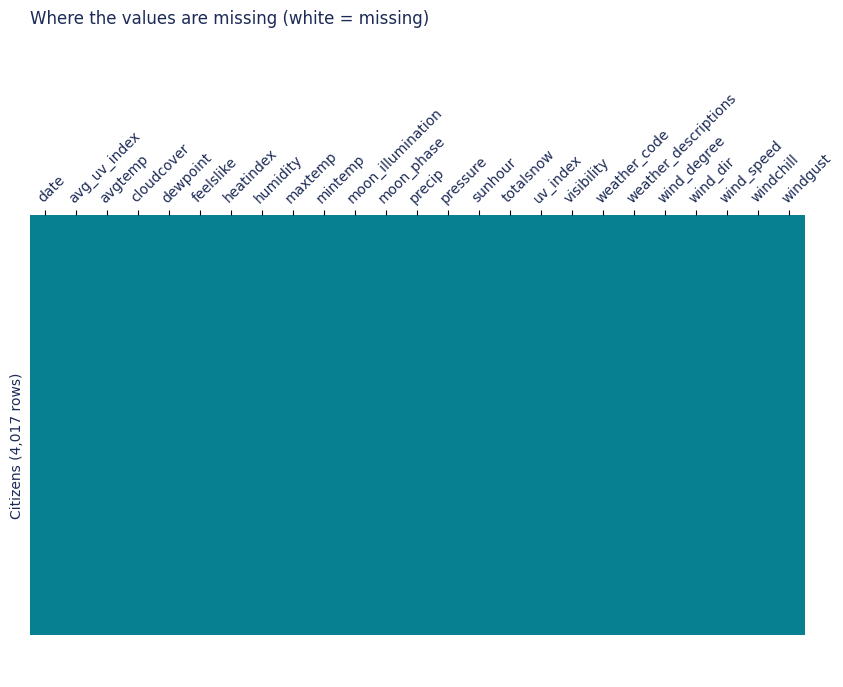

In [377]:
from matplotlib.colors import ListedColormap

NAVY, TEAL = "#1c2a56", "#078091"
FILL = TEAL                    # colour of the cells that have a value
TEXT = NAVY


SORT_ROWS = False              # True: group citizens with the same gaps together (blocks are easier to see)
present = df_weather.notna()
if SORT_ROWS:
    present = present.sort_values(list(present.columns), ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(present.values, aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["white", FILL]), vmin=0, vmax=1)   # True = coloured, NaN = white

ax.set_xticks(range(present.shape[1]))
ax.xaxis.tick_top()
ax.set_xticklabels(present.columns, rotation=45, ha="left", rotation_mode="anchor", color=TEXT)
ax.set_ylabel(f"Citizens ({len(df_weather):,} rows)", color=TEXT)
ax.set_yticks([])
ax.set_title("Where the values are missing (white = missing)", loc="left", color=TEXT, pad=48)
for s in ax.spines.values():
    s.set_visible(False)

plt.show()

In [378]:
df_weather.isna().sum()

date                    365
avg_uv_index            365
avgtemp                 365
cloudcover              365
dewpoint                365
feelslike               365
heatindex               365
humidity                365
maxtemp                 365
mintemp                 365
moon_illumination       365
moon_phase              365
precip                  365
pressure                365
sunhour                 365
totalsnow               365
uv_index                365
visibility              365
weather_code            365
weather_descriptions    365
wind_degree             365
wind_dir                365
wind_speed              365
windchill               365
windgust                365
dtype: int64

no missing values in the weather dataset

In [379]:
print(df_freight.duplicated().sum())
print(df_weather.duplicated().sum())

243
364


there are no duplicates

# Features

In [380]:
df_freight.head(10)

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN
5,2013-01-10,37.05,578.533647,259.139785,581.836410,567.313543,304.0,NaN
6,2013-01-11,37.05,553.267720,249.329516,556.023289,541.716802,297.0,NaN
7,2013-01-14,37.05,548.541638,250.168653,558.254983,544.014828,285.0,NaN
8,2013-01-15,37.05,548.216944,251.444436,561.987579,547.692059,267.0,NaN
9,2013-01-16,37.05,550.397971,250.335166,563.262318,546.577574,251.0,NaN


In [381]:
df_weather.head()

,date,avg_uv_index,avgtemp,cloudcover,dewpoint,feelslike,heatindex,humidity,maxtemp,mintemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,01/01/2009,1.0,-1.0,17.0,-4.0,-6.0,-3.0,95.0,2.0,-5.0,...,0.0,1.0,7.0,113.0,['Clear'],48.0,NE,10.0,-6.0,19.0
1,02/01/2009,1.0,-3.0,63.0,-5.0,-9.0,-3.0,88.0,-2.0,-4.0,...,0.0,1.0,10.0,119.0,['Cloudy'],54.0,NE,17.0,-9.0,26.0
2,03/01/2009,1.0,-7.0,7.0,-12.0,-12.0,-9.0,78.0,-4.0,-11.0,...,0.0,1.0,10.0,113.0,['Clear'],67.0,ENE,6.0,-12.0,13.0
3,04/01/2009,1.0,-8.0,19.0,-12.0,-10.0,-8.0,74.0,-4.0,-10.0,...,0.0,1.0,10.0,116.0,['Partly cloudy'],264.0,W,4.0,-10.0,9.0
4,05/01/2009,1.0,-7.0,74.0,-8.0,-11.0,-6.0,89.0,-5.0,-8.0,...,0.0,1.0,10.0,122.0,['Overcast'],56.0,NE,10.0,-11.0,17.0


In [382]:
#df_freight["freight_ar"] = df_freight["freight_ar"].fillna(0)
#df_freight['Total_Freight'] = df_freight['Freight'] + df_freight['freight_ar']

In [383]:
#df_freight.dropna(subset=['Total_Freight'], inplace=True)
df_freight.shape

(1713, 8)

In [384]:
#df_freight.drop(columns=['Freight', 'freight_ar'], inplace=True)

In [385]:
df_freight.head()

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN


In [386]:
df_weather.drop(columns=['avg_uv_index', 'uv_index'], inplace=True)

In [387]:
df_weather.head()

,date,avgtemp,cloudcover,dewpoint,feelslike,heatindex,humidity,maxtemp,mintemp,moon_illumination,...,sunhour,totalsnow,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,01/01/2009,-1.0,17.0,-4.0,-6.0,-3.0,95.0,2.0,-5.0,31.0,...,8.3,0.0,7.0,113.0,['Clear'],48.0,NE,10.0,-6.0,19.0
1,02/01/2009,-3.0,63.0,-5.0,-9.0,-3.0,88.0,-2.0,-4.0,38.0,...,3.1,0.0,10.0,119.0,['Cloudy'],54.0,NE,17.0,-9.0,26.0
2,03/01/2009,-7.0,7.0,-12.0,-12.0,-9.0,78.0,-4.0,-11.0,45.0,...,8.3,0.0,10.0,113.0,['Clear'],67.0,ENE,6.0,-12.0,13.0
3,04/01/2009,-8.0,19.0,-12.0,-10.0,-8.0,74.0,-4.0,-10.0,52.0,...,8.4,0.0,10.0,116.0,['Partly cloudy'],264.0,W,4.0,-10.0,9.0
4,05/01/2009,-7.0,74.0,-8.0,-11.0,-6.0,89.0,-5.0,-8.0,60.0,...,3.1,0.0,10.0,122.0,['Overcast'],56.0,NE,10.0,-11.0,17.0


Weather correlations

In [388]:
df_freight.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar'],
      dtype='object')

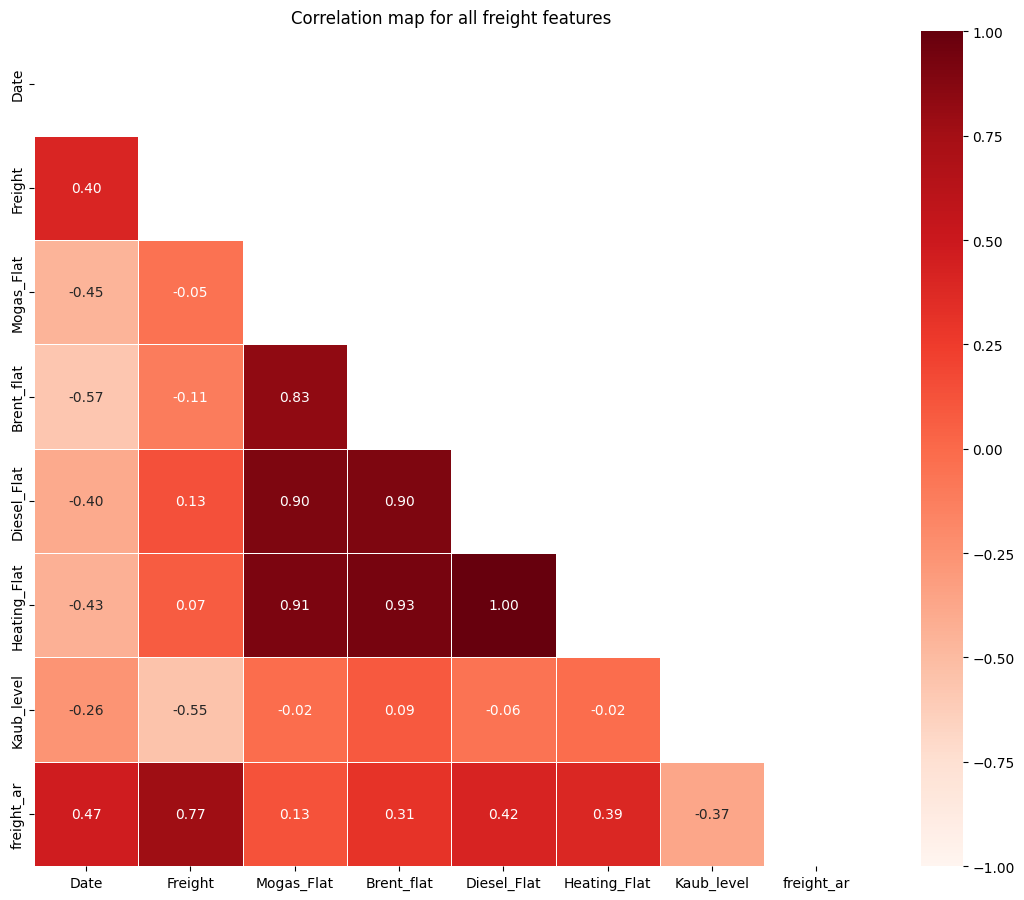

In [389]:

correlation_data = df_freight.copy()

correlation_data["Date"] = pd.to_datetime(correlation_data["Date"])
correlation_data = correlation_data.dropna(subset=["Date"])

correlation_data["Date"] = pd.to_datetime(correlation_data["Date"]).map(
    lambda date: date.toordinal()
)
correlation_matrix = correlation_data.corr(method="pearson")

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    correlation_matrix,
    mask=mask,       # Hides the upper triangle
    annot=True,
    fmt=".2f",
    cmap="Reds",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Correlation map for all freight features")
fig.tight_layout()
plt.show()


- Fuel prices are highly correlated
- Freight prices not correlated with water level and date
- freight_ar correlated with date, fuel and water level. and highly correlated with freight

In [390]:
df_weather.rename(columns={'date': 'Date'}, inplace=True)
df_weather["Date"] = pd.to_datetime(df_weather["Date"], format="%d/%m/%Y")

Encoding 

In [391]:
df_weather[['moon_phase', 'weather_descriptions', 'wind_dir']].nunique()

moon_phase               8
weather_descriptions    17
wind_dir                16
dtype: int64

interval columns not set, guessing: ['Date', 'avgtemp', 'cloudcover', 'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp', 'moon_illumination', 'precip', 'pressure', 'sunhour', 'totalsnow', 'visibility', 'weather_code', 'wind_degree', 'wind_speed', 'windchill', 'windgust']


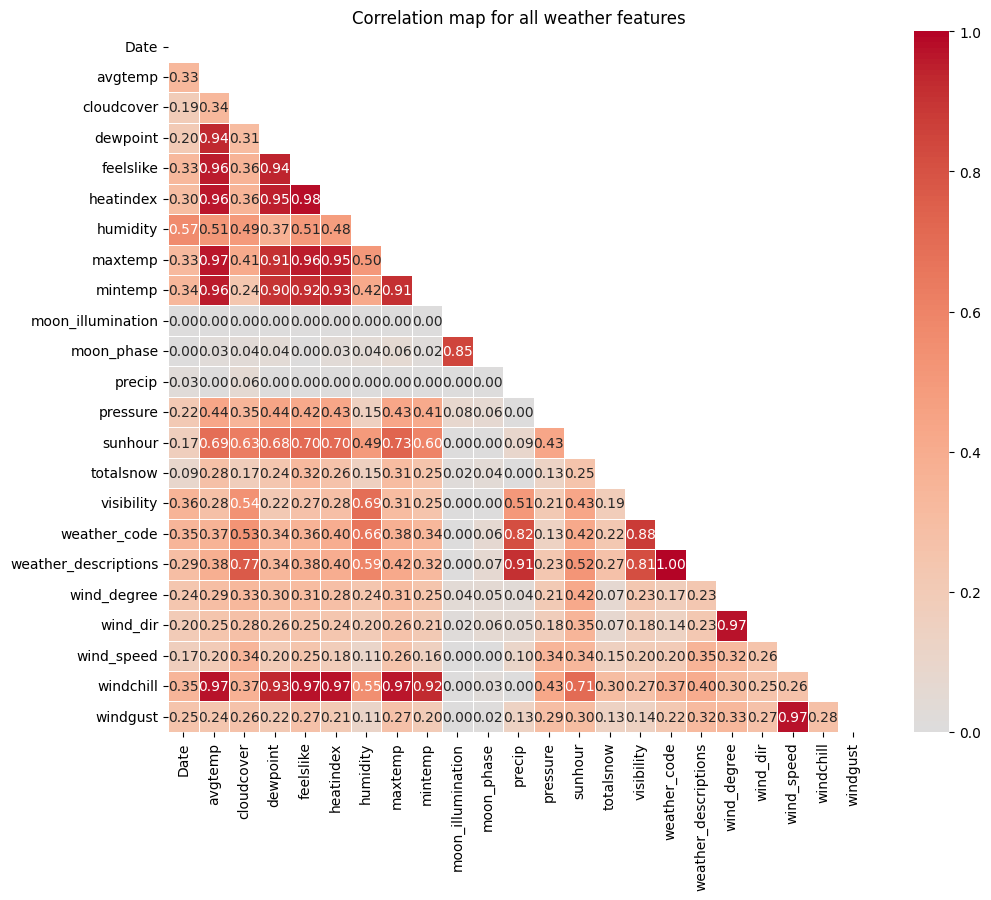

In [392]:
import phik

correlation_wdata = df_weather.copy()
correlation_wdata["Date"] = pd.to_datetime(correlation_wdata["Date"], format="mixed")
correlation_wdata = correlation_wdata.dropna(subset=["Date"])

correlation_wdata["Date"] = pd.to_datetime(correlation_wdata["Date"]).map(
    lambda date: date.toordinal()
)
correlation_matrix = correlation_wdata.phik_matrix()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    correlation_matrix,
    mask=mask,       # Hides the upper triangle
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Correlation map for all weather features")
fig.tight_layout()
plt.show()

- expected correlations between similar features

Joining datasets


In [393]:
df_complete = pd.merge(df_freight, df_weather, on="Date", how='left')
df_complete.head()

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,avgtemp,cloudcover,...,sunhour,totalsnow,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN,2.0,100.0,...,6.8,0.0,10.0,122.0,['Overcast'],245.0,WSW,7.0,1.0,14.0
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN,4.0,100.0,...,3.1,0.0,0.0,248.0,['Fog'],283.0,WNW,6.0,3.0,12.0
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN,1.0,24.0,...,8.4,0.0,10.0,113.0,['Clear'],105.0,ESE,5.0,-2.0,10.0
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN,0.0,3.0,...,8.4,0.0,10.0,113.0,['Clear'],210.0,SSW,4.0,0.0,8.0
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN,-1.0,54.0,...,5.0,0.0,5.0,143.0,['Mist'],273.0,W,5.0,-3.0,10.0


In [394]:
df_complete.shape

(90529, 30)

In [395]:
import numpy as np
import pandas as pd
import phik
import seaborn as sns
import matplotlib.pyplot as plt

correlation_complete_data = df_complete.copy()

correlation_complete_data["Date"] = correlation_complete_data["Date"].map(
    lambda date: date.toordinal()
)

# Calculate Phik matrix (using njobs=1 to prevent Windows crash)
correlation_matrix = correlation_complete_data.phik_matrix(njobs=1)

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# 1. Dynamically scale figure size so cells have enough physical room
n_features = len(correlation_matrix.columns)
fig_size = max(10, n_features * 0.8)
fig, ax = plt.subplots(figsize=(fig_size, fig_size))

# 2. Dynamically shrink text size so numbers fit cleanly inside the cells
font_size = max(5, 14 - (n_features * 0.1))

sns.heatmap(
    correlation_matrix,
    mask=mask,  # Hides the upper triangle
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    # center=0 removed because phik ranges from 0 to 1
    square=True,
    linewidths=0.5,
    annot_kws={"size": font_size},  # Forces annotations to scale down
    ax=ax,
)

# 3. Rotate and adjust tick labels to prevent crowding
plt.xticks(
    rotation=45, ha="right", fontsize=max(8, 12 - int(n_features * 0.15))
)
plt.yticks(rotation=0, fontsize=max(8, 12 - int(n_features * 0.15)))

ax.set_title("Correlation map for all features", fontsize=14, pad=15)
fig.tight_layout()
plt.show()

ValueError: NaTType does not support toordinal

In [ ]:
df_complete.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar', 'avgtemp', 'cloudcover',
       'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp',
       'moon_illumination', 'moon_phase', 'precip', 'pressure', 'sunhour',
       'totalsnow', 'visibility', 'weather_code', 'weather_descriptions',
       'wind_degree', 'wind_dir', 'wind_speed', 'windchill', 'windgust'],
      dtype='object')

In [396]:
relevant_columns = ['windchill', 'sunhour', 'maxtemp', 'mintemp', 'avgtemp', 'freight_ar', 'Kaub_level', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat']

df_complete['freight_ar'] = df_complete['freight_ar'].fillna(0)
df_complete['Freight_total'] = df_complete['Freight'] + df_complete['freight_ar']

target = ['Freight_total']

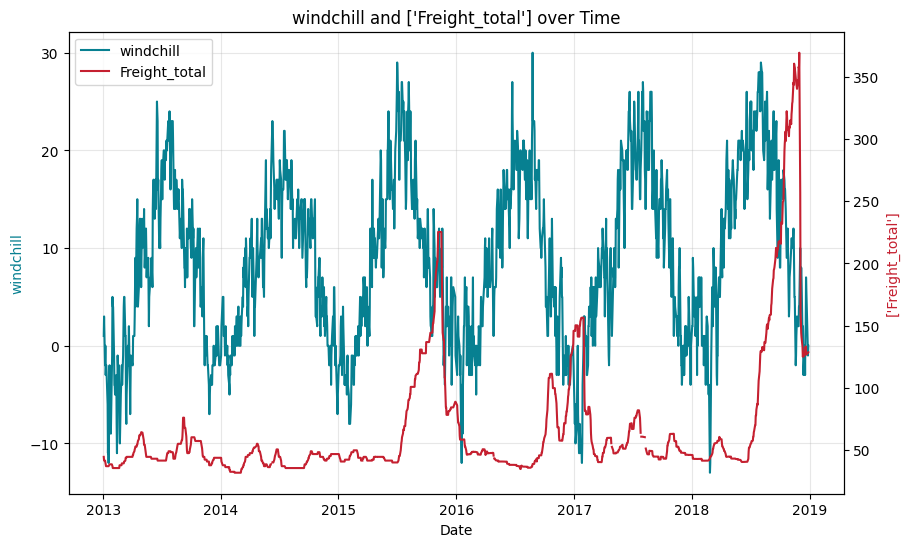

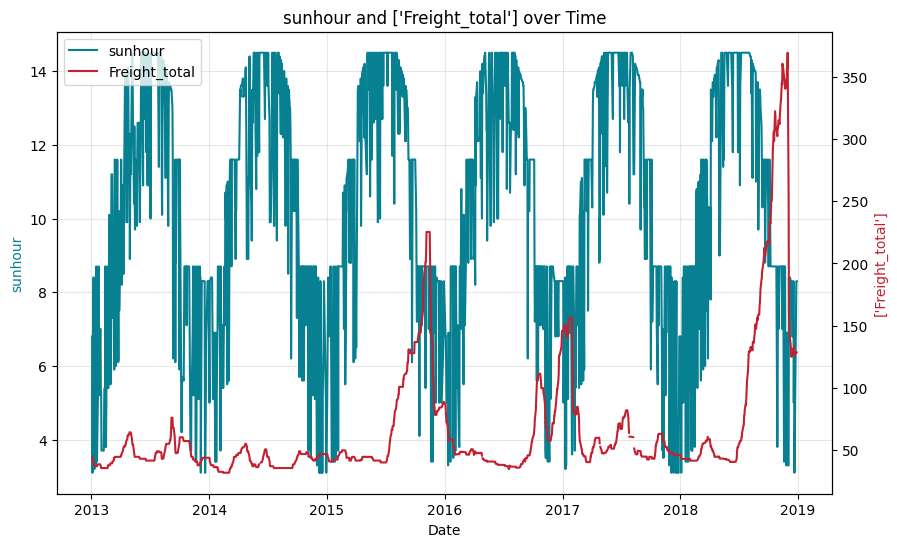

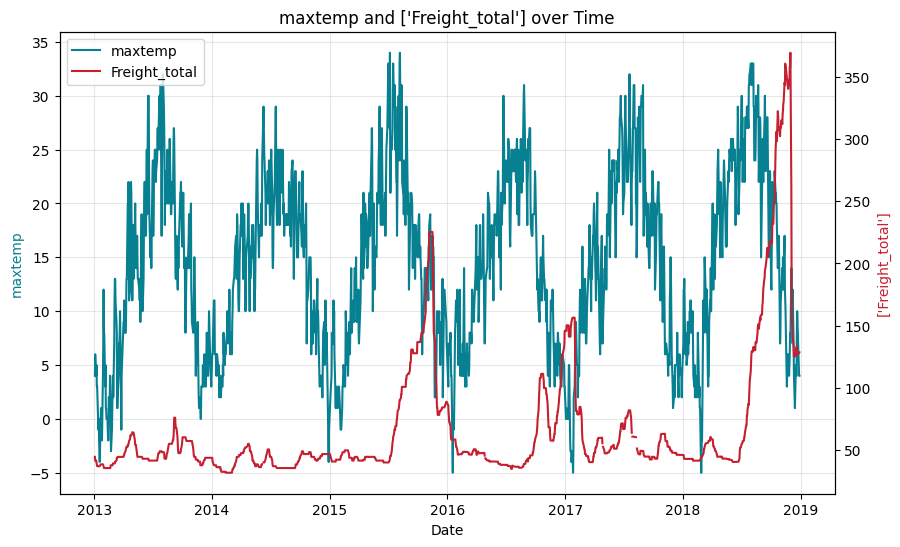

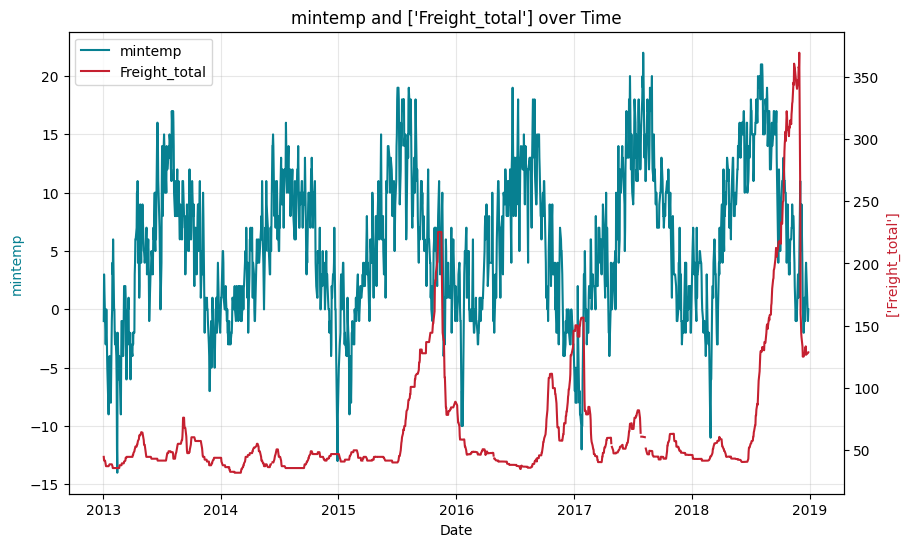

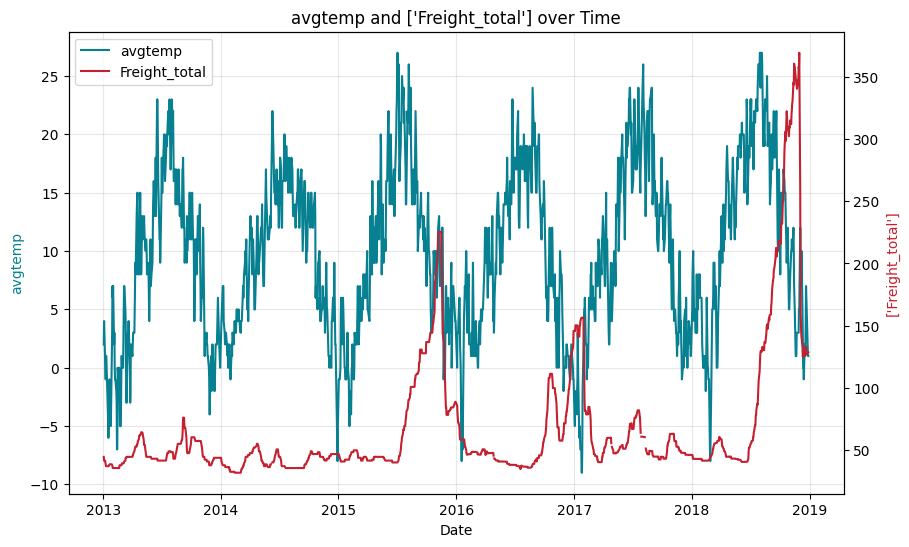

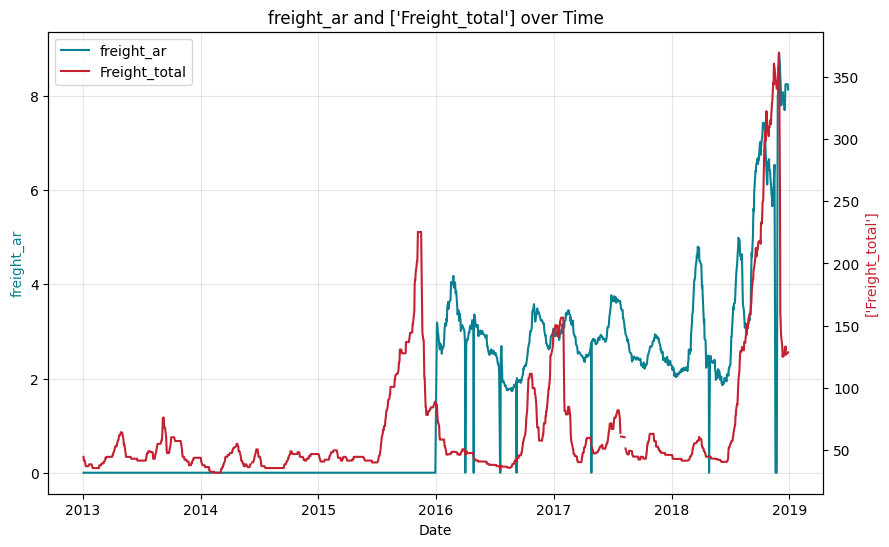

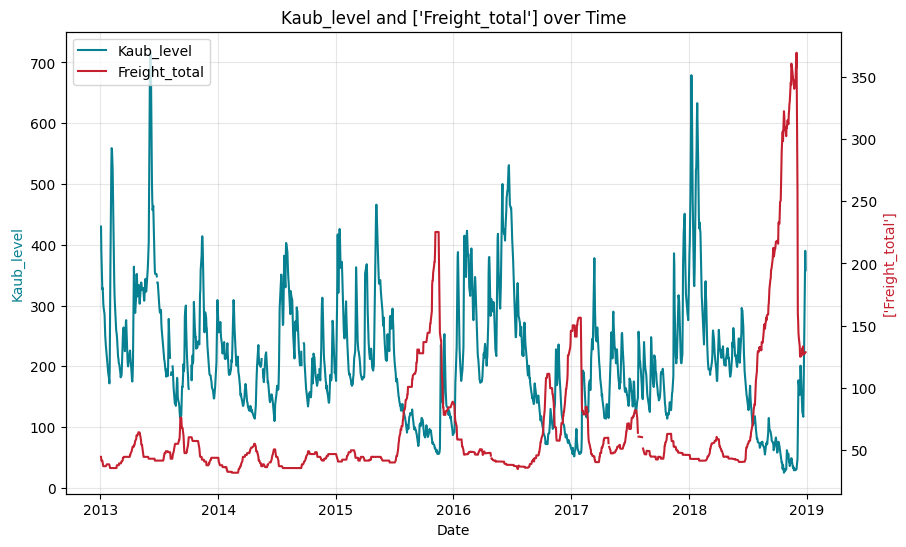

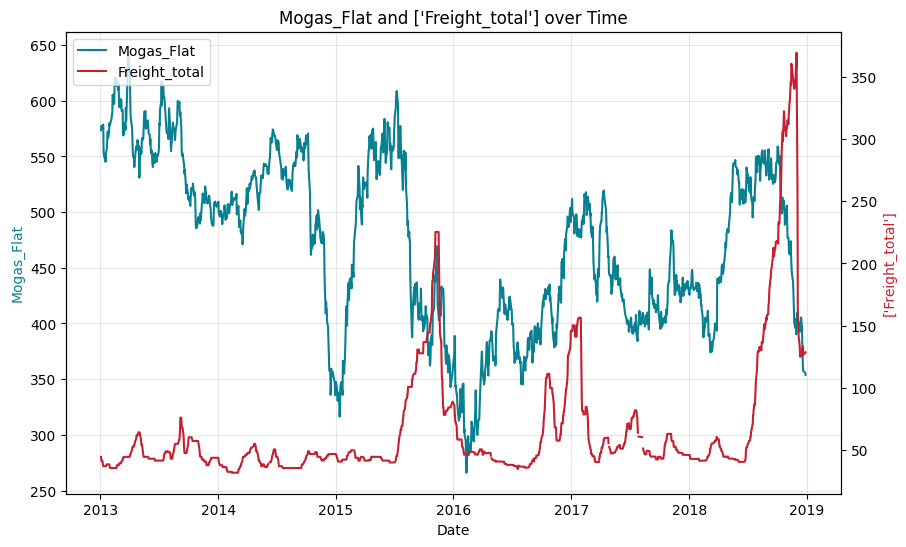

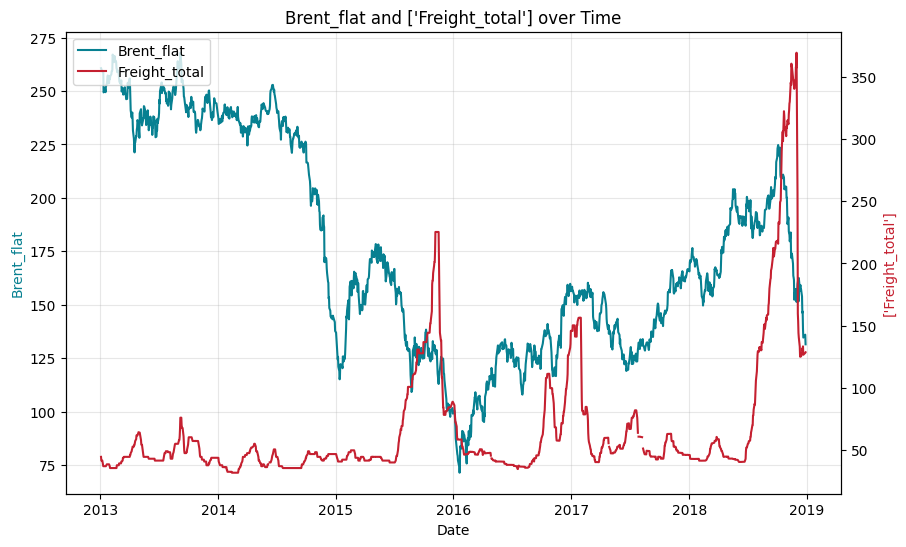

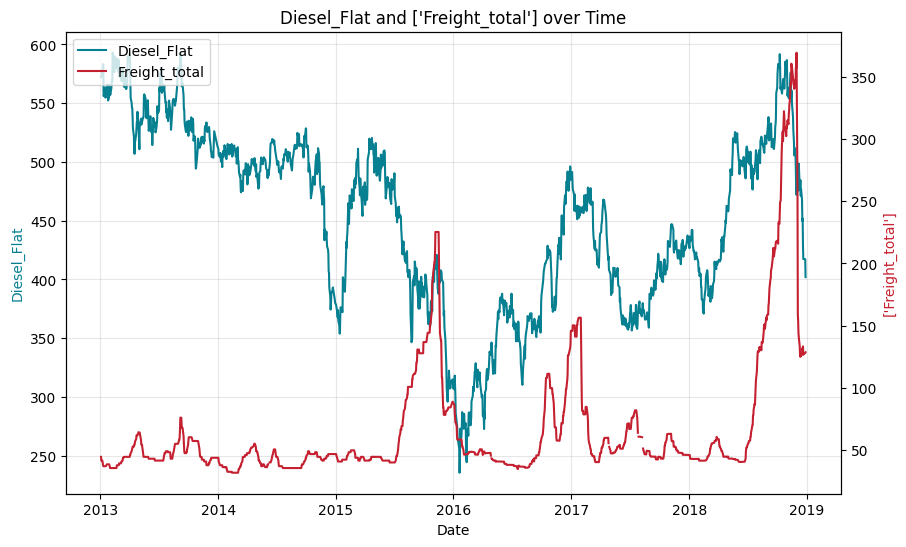

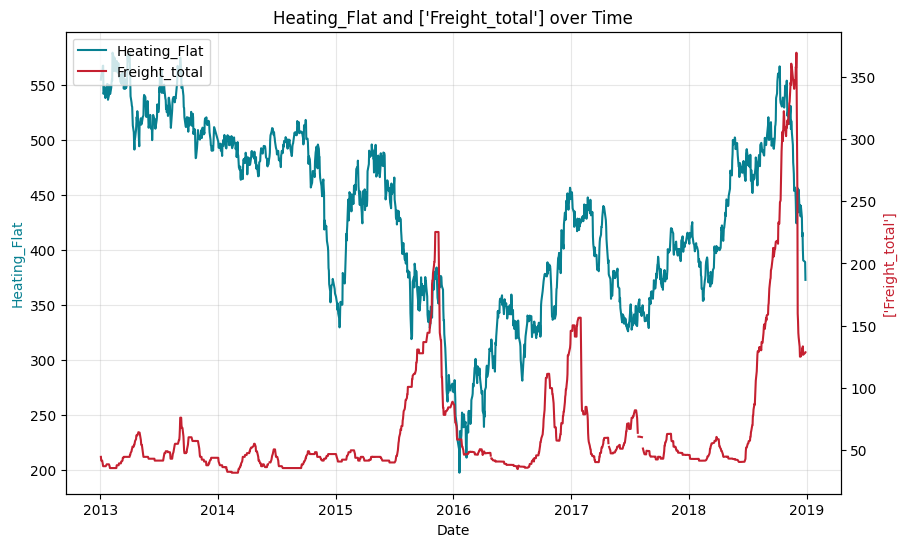

In [397]:
for variable in relevant_columns:
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(df_complete["Date"], df_complete[variable], color="#078091", label=variable)
    ax.set_ylabel(variable, color="#078091")
    ax.grid(True, alpha=0.3)

    ax2 = ax.twinx()
    ax2.plot(df_complete["Date"], df_complete[target], color="#c52030", label=target)
    ax2.set_ylabel(target, color="#c52030")

    # one legend for both lines
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left")

    ax.set_title(f"{variable} and {target} over Time")
    ax.set_xlabel("Date")
    plt.show()

- some weather features are periodical and the correlation table showed that there was some correlation to freight prices, however these seem random
- fuels and target seem lightly correlated but not apparent if it was chance or not
- big spike in freight prices in the last year which is not really explained through the features, although fuel prices also increased at that time
- the two different freights follow the same trend

In [ ]:
df_complete.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar', 'avgtemp', 'cloudcover',
       'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp',
       'moon_illumination', 'moon_phase', 'precip', 'pressure', 'sunhour',
       'totalsnow', 'visibility', 'weather_code', 'weather_descriptions',
       'wind_degree', 'wind_dir', 'wind_speed', 'windchill', 'windgust',
       'Freight_total'],
      dtype='object')

In [398]:
kaul_level_relevant = ['Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'sunhour']

target_kaul = ['Kaub_level']

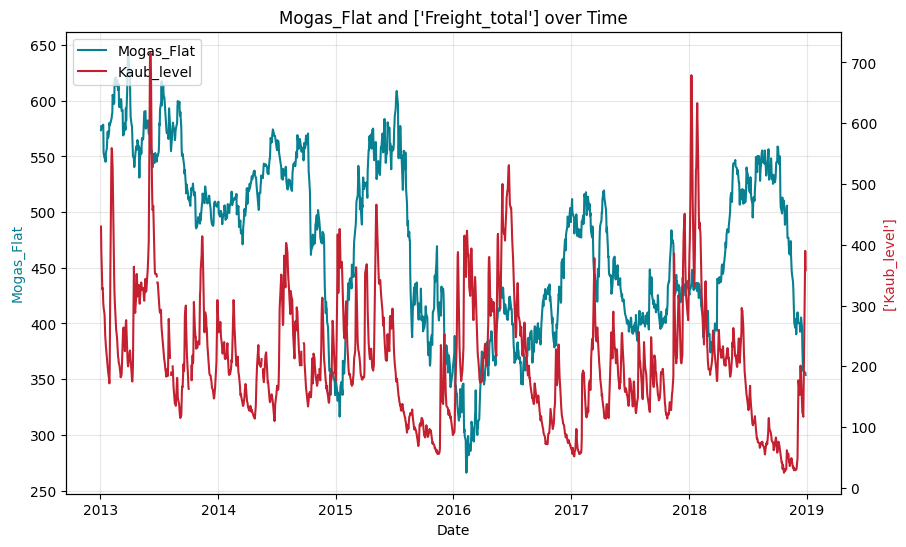

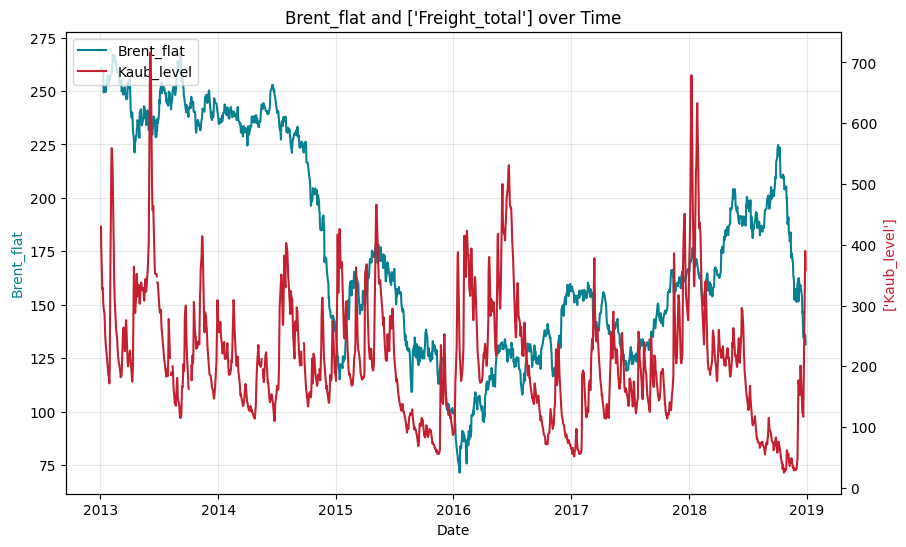

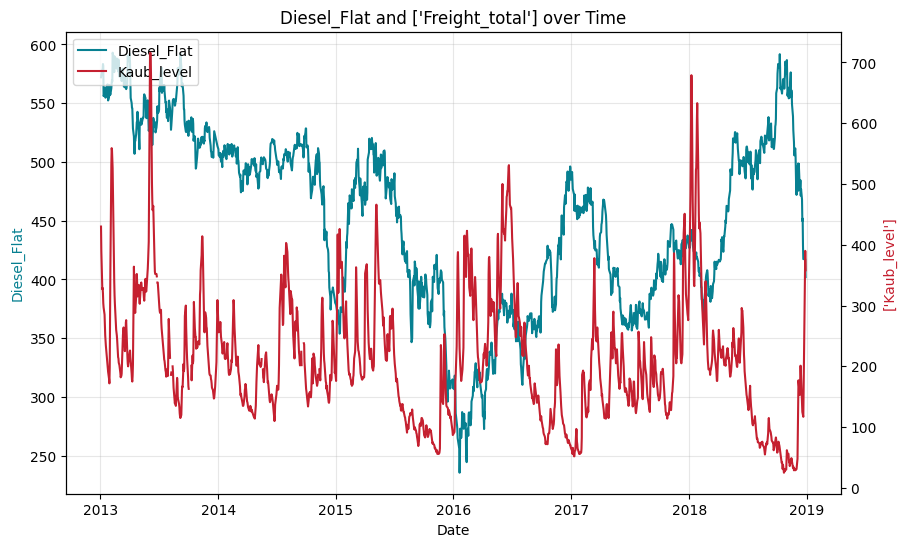

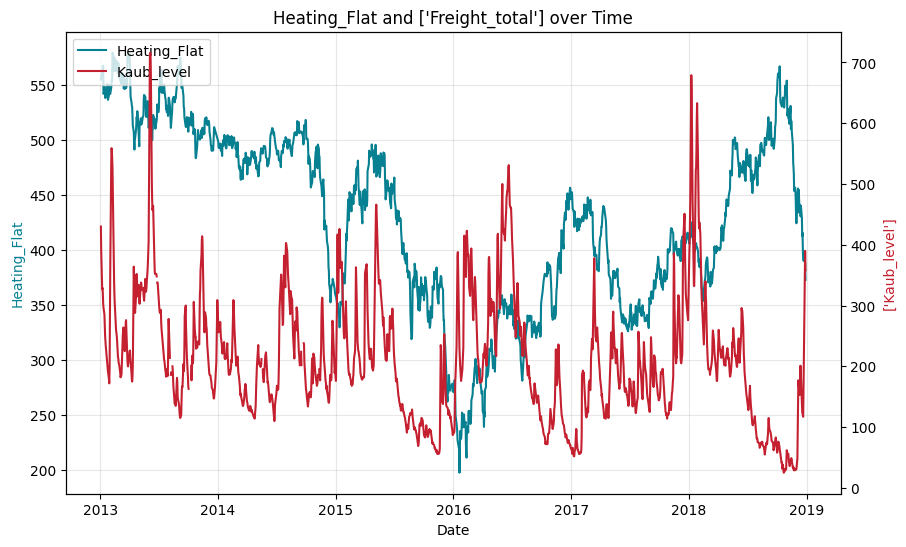

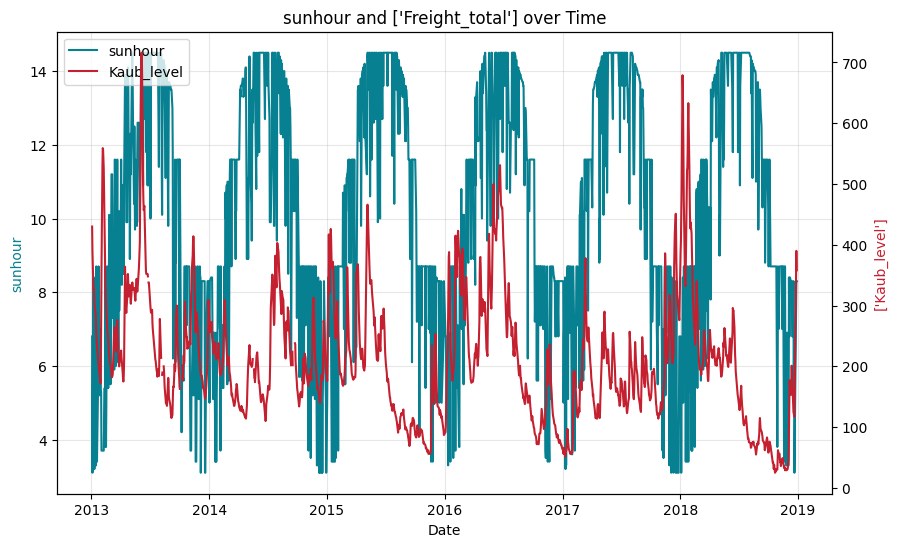

In [399]:
for variable in kaul_level_relevant:
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(df_complete["Date"], df_complete[variable], color="#078091", label=variable)
    ax.set_ylabel(variable, color="#078091")
    ax.grid(True, alpha=0.3)

    ax2 = ax.twinx()
    ax2.plot(df_complete["Date"], df_complete[target_kaul], color="#c52030", label=target_kaul)
    ax2.set_ylabel(target_kaul, color="#c52030")

    # one legend for both lines
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left")

    ax.set_title(f"{variable} and {target} over Time")
    ax.set_xlabel("Date")
    plt.show()

- no clear trend by te graphs

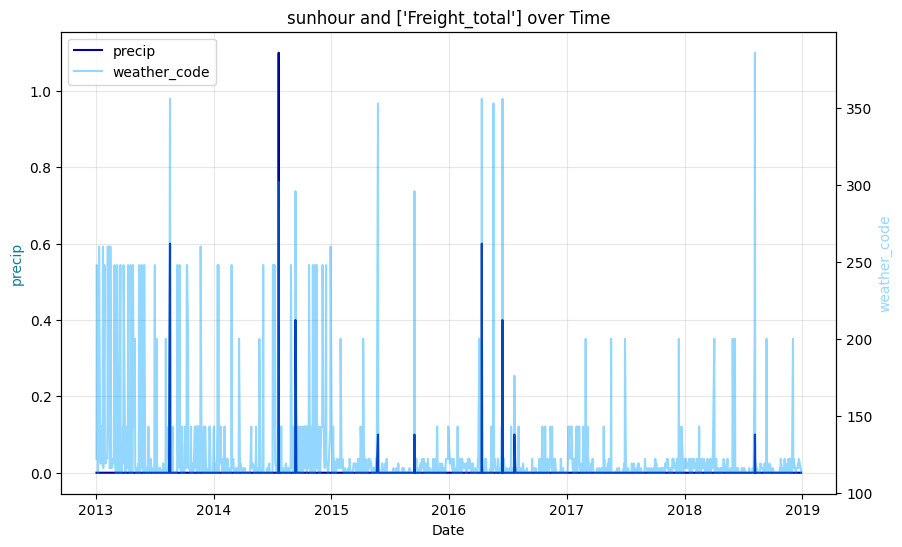

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(df_complete["Date"], df_complete['precip'], color="#00039C", label='precip')
ax.set_ylabel('precip', color="#078091")
ax.grid(True, alpha=0.3)

ax2 = ax.twinx()
ax2.plot(df_complete["Date"], df_complete['weather_code'], color="#00a2ff6c", label='weather_code')
ax2.set_ylabel('weather_code', color="#00a2ff6c")

# one legend for both lines
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()

ax.legend(h1 + h2, l1 + l2, loc="upper left")
ax.set_title(f"{variable} and {target} over Time")
ax.set_xlabel("Date")
plt.show()

In [ ]:
df_complete[df_complete['weather_code'].isin([386, 359, 356, 353, 305, 302, 296])]

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,avgtemp,cloudcover,...,totalsnow,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust,Freight_total
153,2013-08-19,52.80,574.791543,250.607014,552.980270,538.856235,144.0,NaN,16,23,...,0.0,8,356,['Moderate or heavy rain shower'],315,NW,7,15,14,NaN
377,2014-07-22,35.55,538.799970,236.087827,498.988655,492.193787,270.0,NaN,17,100,...,0.0,5,302,['Moderate rain'],212,SSW,9,18,15,NaN
413,2014-09-12,35.55,565.454901,223.416596,513.889146,506.546346,202.0,NaN,10,95,...,0.0,9,296,['Light rain'],242,WSW,6,10,12,NaN
582,2015-05-26,41.55,570.566301,170.400879,505.267213,484.597279,290.0,NaN,11,59,...,0.0,10,353,['Light rain shower'],292,WNW,12,10,20,NaN
661,2015-09-16,130.80,417.914809,130.388315,398.378109,366.270631,77.0,NaN,13,45,...,0.0,9,296,['Light rain'],105,ESE,11,11,22,NaN
802,2016-04-12,44.55,376.154886,113.039663,316.745721,286.827902,209.0,2.99,12,80,...,0.0,8,356,['Moderate or heavy rain shower'],226,SW,6,11,13,47.54
825,2016-05-18,37.80,411.934612,131.022254,372.340130,344.296745,418.0,3.02,12,42,...,0.0,10,353,['Light rain shower'],195,SSW,10,16,14,40.82
843,2016-06-15,35.55,404.396408,127.239537,372.391762,345.721968,481.0,2.55,11,91,...,0.0,8,356,['Moderate or heavy rain shower'],177,S,10,10,17,38.10
1372,2018-08-07,128.10,544.645633,188.114118,507.135358,484.560898,72.0,4.64,26,21,...,0.0,10,386,['Patchy light rain with thunder'],177,S,8,28,14,132.74


- weather codes match the precipitation levels

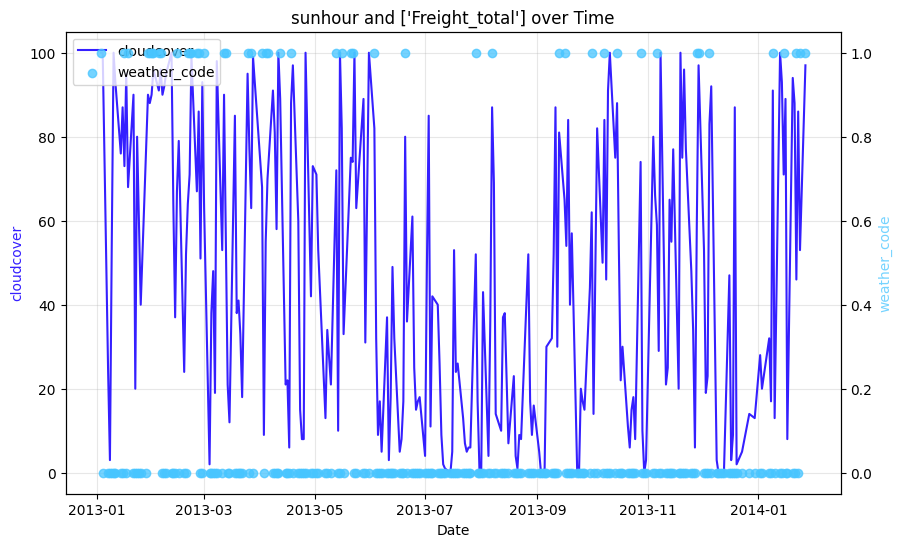

In [ ]:
cloud_codes = df_complete['weather_code'].isin([119, 122])

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(df_complete["Date"].head(int(365*5/7)), df_complete['cloudcover'].head(int(365*5/7)), color="#351FFFFF", label='cloudcover')
ax.set_ylabel('cloudcover', color="#351FFFFF")
ax.grid(True, alpha=0.3)

ax2 = ax.twinx()
ax2.scatter(df_complete["Date"].head(int(365*5/7)), cloud_codes.head(int(365*5/7)), color="#48c5ffc1", label='weather_code')
ax2.set_ylabel('weather_code', color="#48c5ffc1")

# one legend for both lines
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()

ax.legend(h1 + h2, l1 + l2, loc="upper left")
ax.set_title(f"{variable} and {target} over Time")
ax.set_xlabel("Date")
plt.show()

- not super clear but weather codes related to cloudy sky seem to show up when cloudcover values are higher, expected

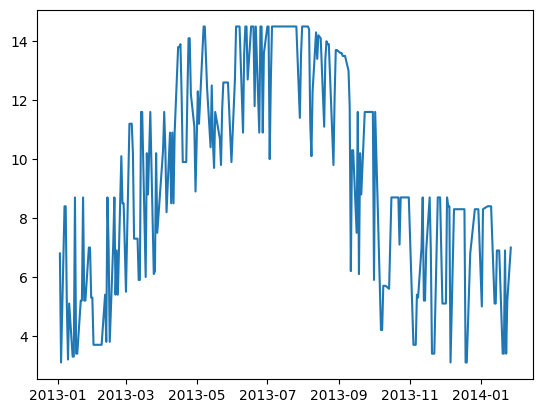

In [ ]:
plt.plot(df_complete["Date"].head(int(365*5/7)), df_complete['sunhour'].head(int(365*5/7)))
plt.show()

relation between windchill and highly correlated variables

In [ ]:
df_complete.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar', 'avgtemp', 'cloudcover',
       'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp',
       'moon_illumination', 'moon_phase', 'precip', 'pressure', 'sunhour',
       'totalsnow', 'visibility', 'weather_code', 'weather_descriptions',
       'wind_degree', 'wind_dir', 'wind_speed', 'windchill', 'windgust',
       'Freight_total'],
      dtype='object')

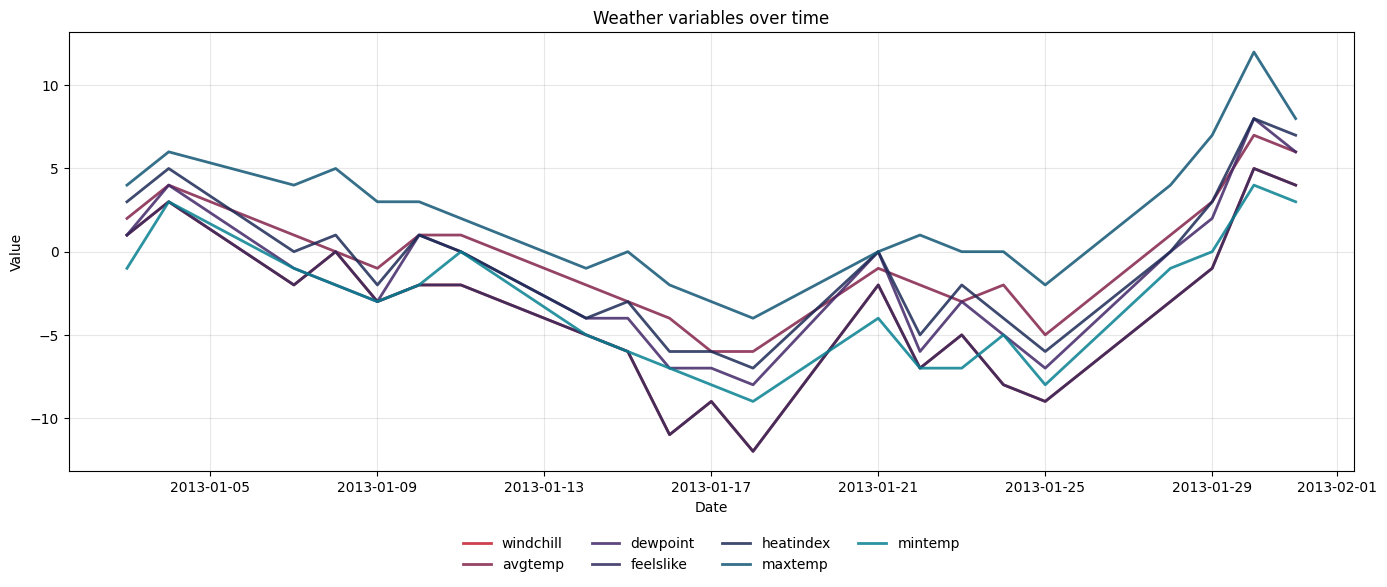

In [ ]:
cols = ['windchill', 'avgtemp', 'dewpoint', 'feelslike', 'heatindex', 'maxtemp', 'mintemp']

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list("closer", ["#c52030", "#422767", "#1c2a56", "#078091"])
colors = [cmap(i / (len(cols) - 1)) for i in range(len(cols))]

d = df_complete.sort_values("Date").head(int(365*5/7 / 12))  # Use the first 5/7 of the year for plotting


fig, ax = plt.subplots(figsize=(14, 6))
for col, color in zip(cols, colors):
    ax.plot(d["Date"], d[col], label=col, color=color, lw=2, alpha=0.85)

ax.set_title("Weather variables over time")
ax.set_xlabel("Date")
ax.set_ylabel("Value")
ax.grid(True, alpha=0.3)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout()
plt.show()